In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt


Text(0.5, 1.0, 'Face')

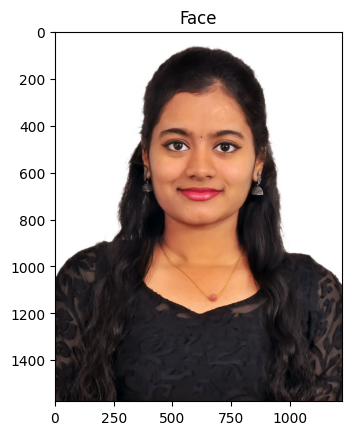

In [2]:

# Load the Face Image
faceImage = cv2.imread('photo.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")

In [3]:
faceImage.shape


(1575, 1225, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(1575, 1225, 3)

Text(0.5, 1.0, 'glassPNG')

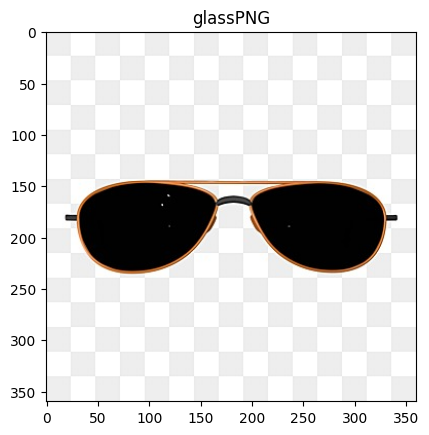

In [38]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('/content/pngtree-aviators-sunglasses-with-brown-frames-png-image_4504393.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [45]:
# Target coordinates
y1, y2 = 410, 680
x1, x2 = 480, 880

# Resize the image to fit over the eye region properly keeping the target aspect ratio
glassPNG = cv2.resize(glassPNG, (x2 - x1, y2 - y1))
print("image Dimension = {}".format(glassPNG.shape))

image Dimension = (270, 400, 3)


In [54]:
# Separate the Color and handle alpha channel creation
glassBGR = glassPNG[:, :, 0:3]

# Convert to grayscale
gray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)

# Create a mask where only the dark pixels (sunglasses) are active.
# Since the checkerboard background has light gray (around 220+) and white (255) pixels,
# the sunglasses frame and lenses are significantly darker (typically < 100).
_, glassMask1 = cv2.threshold(gray, 180, 255, cv2.THRESH_BINARY_INV)

# Use morphological closing and opening to seal the interior of the lenses and clean up any tiny noise
kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
glassMask1 = cv2.morphologyEx(glassMask1, cv2.MORPH_CLOSE, kernel_close)
glassMask1 = cv2.morphologyEx(glassMask1, cv2.MORPH_OPEN, kernel_open)

print("Color shape:", glassBGR.shape)
print("Mask shape:", glassMask1.shape)

Color shape: (270, 400, 3)
Mask shape: (270, 400)


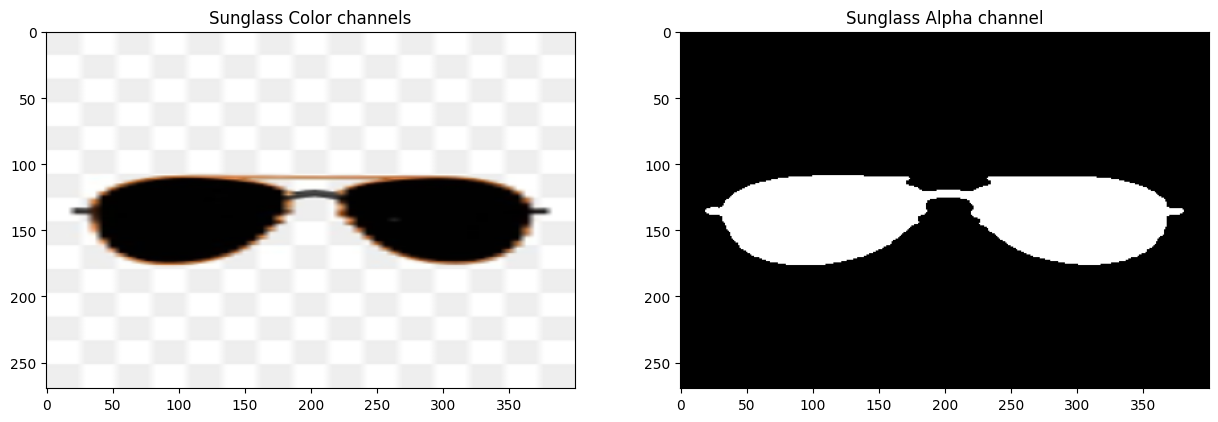

In [55]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

Text(0.5, 1.0, 'Naive Sunglasses Overlay')

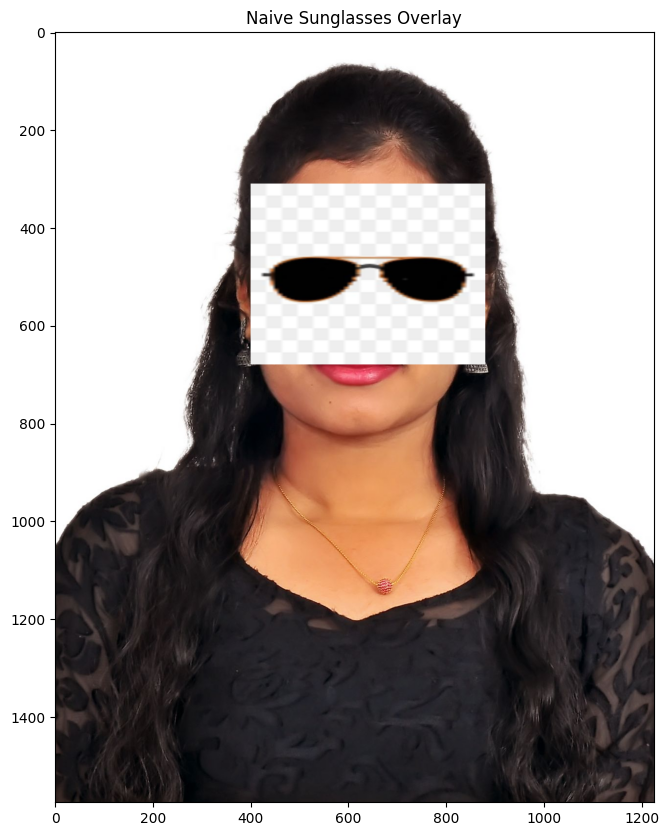

In [57]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Expanded coordinates to make the sunglasses larger
y1, y2 = 310, 680
x1, x2 = 400, 880

# Resize the glassBGR to fit the target slice
glassBGR_naive_resized = cv2.resize(glassBGR, (x2 - x1, y2 - y1))

# Replace the eye region with the sunglass image
faceWithGlassesNaive[y1:y2, x1:x2] = glassBGR_naive_resized

plt.figure(figsize=[10,10])
plt.imshow(faceWithGlassesNaive[...,::-1])
plt.title("Naive Sunglasses Overlay")


Text(0.5, 1.0, 'Augmented Eye and Sunglass')

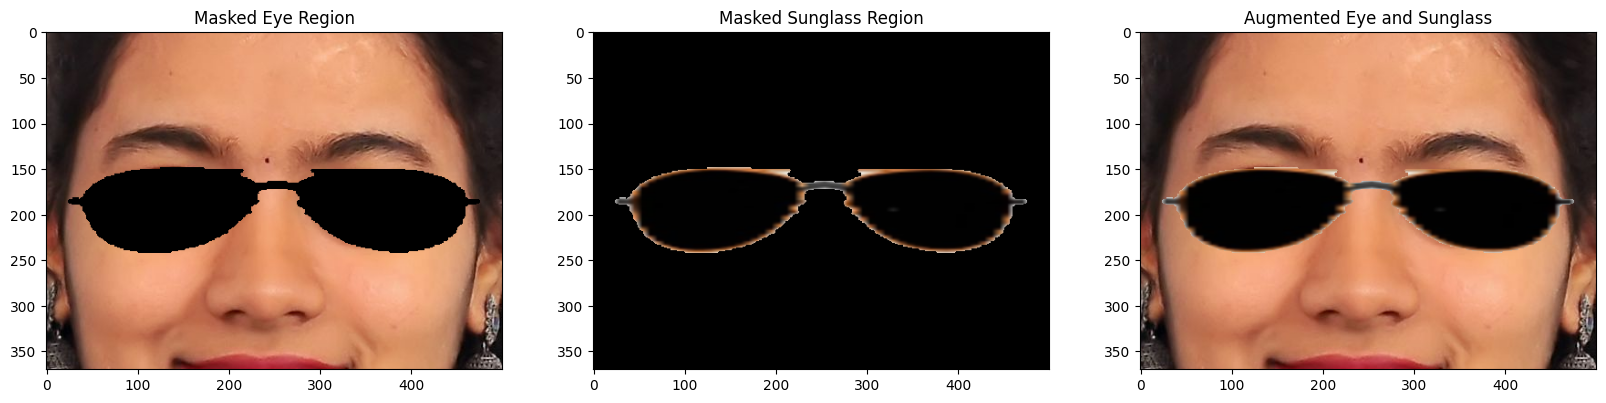

In [62]:
# Make the dimensions of the mask same as the input image.
# Since Face Image is a 3-channel image, we create a 3 channel image for the mask
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Make the values [0,1] since we are using arithmetic operations
glassMask = np.uint8(glassMask/255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the correct eye region from the high-res face image (expanded bounds)
y1, y2 = 410, 680
x1, x2 = 480, 880
eyeROI = faceWithGlassesArithmetic[y1:y2, x1:x2]

# Resize the glassMask to match the eyeROI dimensions
glassMask = cv2.resize(glassMask, (eyeROI.shape[1], eyeROI.shape[0]))

# Resize glassBGR to match the eyeROI dimensions
glassBGR_resized = cv2.resize(glassBGR, (eyeROI.shape[1], eyeROI.shape[0]))

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR_resized, glassMask)

# Combine the Sunglass in the Eye Region to get the augmented image
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the intermediate results
plt.figure(figsize=[20,20])
plt.subplot(131);plt.imshow(maskedEye[...,::-1]);plt.title("Masked Eye Region")
plt.subplot(132);plt.imshow(maskedGlass[...,::-1]);plt.title("Masked Sunglass Region")
plt.subplot(133);plt.imshow(eyeRoiFinal[...,::-1]);plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

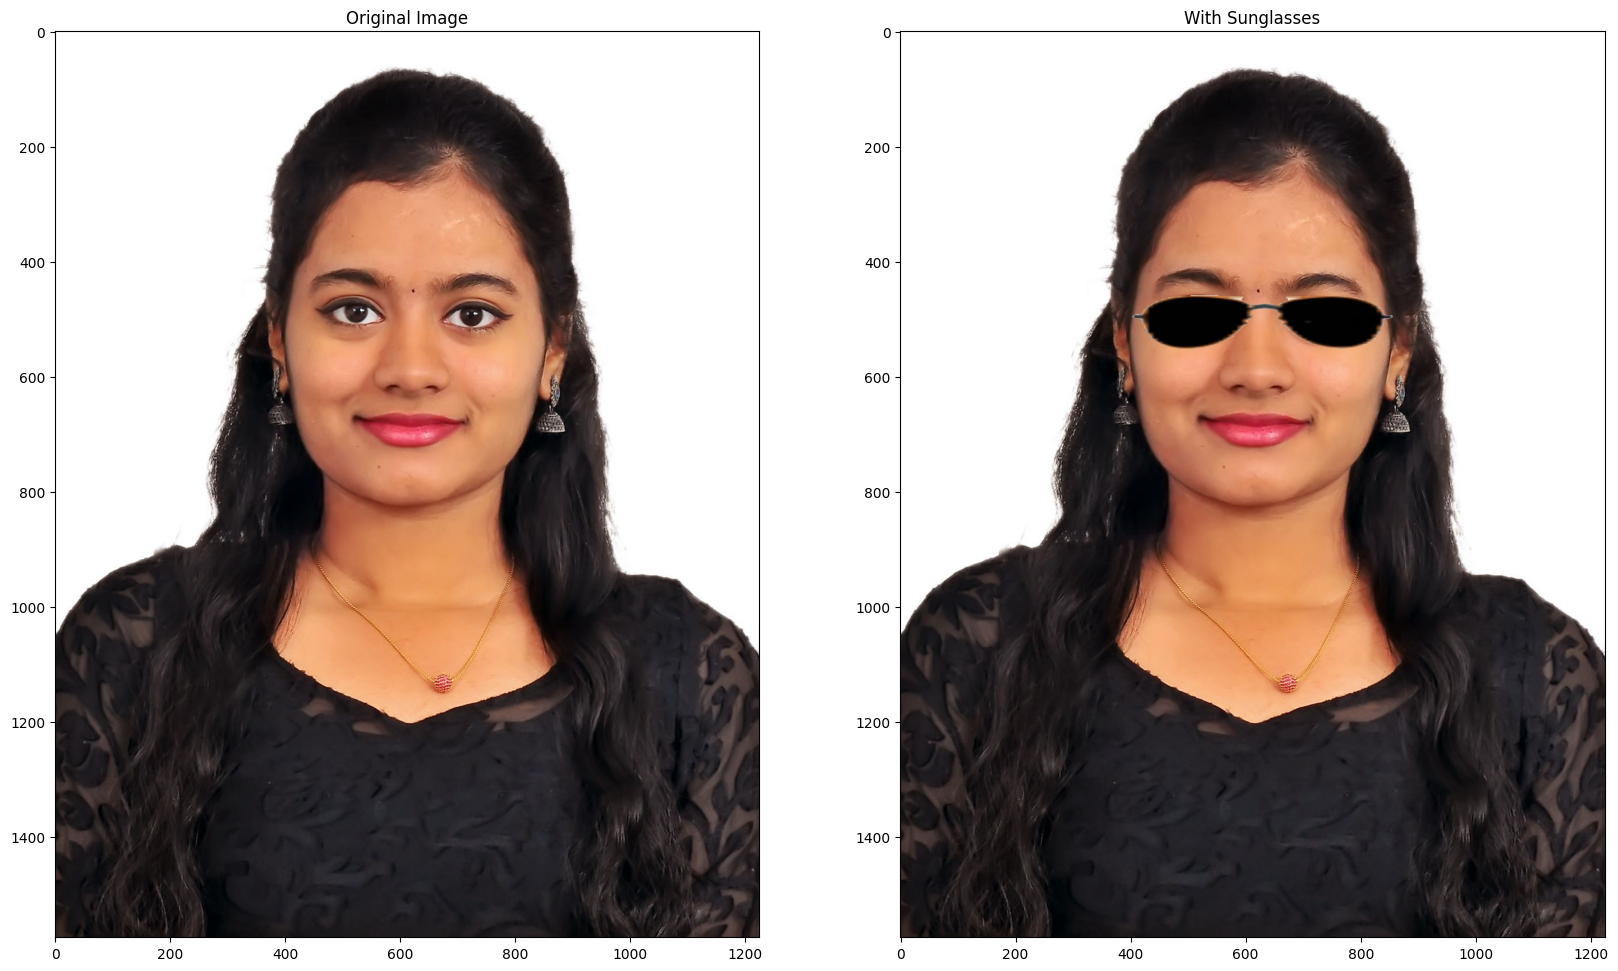

In [66]:
# Replace the eye ROI with the output from the previous section
y1, y2 = 410, 680
x1, x2 = 480, 880
faceWithGlassesArithmetic[y1:y2, x1:x2] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20])
plt.subplot(121);plt.imshow(faceImage[:,:,::-1]); plt.title("Original Image")
plt.subplot(122);plt.imshow(faceWithGlassesArithmetic[:,:,::-1]);plt.title("With Sunglasses")